In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("C:/Users/admin/Downloads/task8_sales_data.csv", parse_dates=["order_date"])
df["month_label"] = df["order_date"].dt.strftime("%b %Y")
print(df.shape)
df.head()

(988, 17)


,order_id,order_date,year,month_number,month_name,is_weekend,customer_id,first_name,last_name,item_id,item_name,category_name,order_type,quantity,unit_price,subtotal,month_label
0,26,2026-01-01,2026,1,January,0,15,Lea,Pascual,12,Brewed Coffee,Beverage,Dine-In,1,60,60,Jan 2026
1,26,2026-01-01,2026,1,January,0,15,Lea,Pascual,9,Iced Tea,Beverage,Dine-In,1,45,45,Jan 2026
2,26,2026-01-01,2026,1,January,0,15,Lea,Pascual,8,Leche Flan,Dessert,Dine-In,3,70,210,Jan 2026
3,51,2026-01-02,2026,1,January,0,25,Faith,Herrera,4,Pancit Canton,Main Course,Delivery,1,120,120,Jan 2026
4,51,2026-01-02,2026,1,January,0,25,Faith,Herrera,3,Beef Caldereta,Main Course,Delivery,1,220,220,Jan 2026


In [2]:
print("Rows (line items):", len(df))
print("Distinct orders  :", df["order_id"].nunique())
print("Date range       :", df["order_date"].min().date(), "to", df["order_date"].max().date())
print("Missing values   :", int(df.isna().sum().sum()))

Rows (line items): 988
Distinct orders  : 450
Date range       : 2026-01-01 to 2026-09-30
Missing values   : 0


In [3]:
total_revenue = df["subtotal"].sum()
total_orders  = df["order_id"].nunique()
items_sold    = df["quantity"].sum()
avg_order_val = total_revenue / total_orders

pd.DataFrame({"total_revenue": [total_revenue], "total_orders": [total_orders],
              "total_items_sold": [items_sold], "avg_order_value": [avg_order_val]})

,total_revenue,total_orders,total_items_sold,avg_order_value
0,157650,450,1490,350.33


In [4]:
total_revenue = df["subtotal"].sum()
total_orders  = df["order_id"].nunique()
items_sold    = df["quantity"].sum()
avg_order_val = total_revenue / total_orders

pd.DataFrame({"total_revenue": [total_revenue], "total_orders": [total_orders],
              "total_items_sold": [items_sold], "avg_order_value": [avg_order_val]})

,total_revenue,total_orders,total_items_sold,avg_order_value
0,157650,450,1490,350.33


In [5]:
q3 = (df.groupby(["item_id", "item_name"])
        .agg(units_sold=("quantity", "sum"), revenue=("subtotal", "sum"))
        .reset_index()
        .sort_values(["units_sold", "revenue"], ascending=False)
        .head(5))
q3

,item_id,item_name,units_sold,revenue
2,3,Beef Caldereta,138,30360
5,6,Calamares,127,16510
11,12,Brewed Coffee,126,7560
10,11,Soda,126,5040
3,4,Pancit Canton,125,15000


In [6]:
q4 = (df.groupby(["year", "month_number", "month_label"])
        .agg(orders=("order_id", "nunique"), revenue=("subtotal", "sum"))
        .reset_index().sort_values(["year", "month_number"]))
q4

,year,month_number,month_label,orders,revenue
0,2026,1,Jan 2026,62,22300
1,2026,2,Feb 2026,45,14480
2,2026,3,Mar 2026,55,20075
3,2026,4,Apr 2026,38,12145
4,2026,5,May 2026,59,16995
5,2026,6,Jun 2026,47,19535
6,2026,7,Jul 2026,48,17600
7,2026,8,Aug 2026,43,16700
8,2026,9,Sep 2026,53,17820


In [7]:
q5 = (df.groupby("order_type")
        .agg(orders=("order_id", "nunique"), items_sold=("quantity", "sum"), revenue=("subtotal", "sum"))
        .sort_values("revenue", ascending=False).reset_index())
q5

,order_type,orders,items_sold,revenue
0,Dine-In,245,833,87570
1,Takeout,109,359,39890
2,Delivery,96,298,30190


In [8]:
q6 = (df.assign(customer_name=df["first_name"] + " " + df["last_name"])
        .groupby(["customer_id", "customer_name"])
        .agg(total_orders=("order_id", "nunique"), total_spent=("subtotal", "sum"))
        .reset_index().sort_values("total_spent", ascending=False).head(5))
q6

,customer_id,customer_name,total_orders,total_spent
1,2,Juan Reyes,34,13300
0,1,Maria Santos,25,10145
9,10,Paolo Aquino,25,9080
3,4,Jose Bautista,25,8090
21,22,Alex Rivera,20,7965


In [9]:
q7 = (df.assign(day_type=df["is_weekend"].map({1: "Weekend", 0: "Weekday"}))
        .groupby("day_type")
        .agg(orders=("order_id", "nunique"), revenue=("subtotal", "sum"), avg_line_value=("subtotal", "mean"))
        .sort_values("revenue", ascending=False).reset_index())
q7

,day_type,orders,revenue,avg_line_value
0,Weekday,274,99330,163.10
1,Weekend,176,58320,153.88


In [10]:
order_totals = df.groupby(["order_id", "order_type"])["subtotal"].sum().reset_index(name="order_total")
q8 = (order_totals.groupby("order_type")["order_total"]
        .agg(orders="count", avg_order_value="mean", smallest_order="min", largest_order="max")
        .sort_values("avg_order_value", ascending=False).reset_index())
q8

,order_type,orders,avg_order_value,smallest_order,largest_order
0,Takeout,109,365.96,40,1310
1,Dine-In,245,357.43,40,1140
2,Delivery,96,314.48,40,955


In [11]:
by_item = (df.groupby(["category_name", "item_id", "item_name"])
             .agg(units_sold=("quantity", "sum"), revenue=("subtotal", "sum")).reset_index())
by_item["rank_in_category"] = by_item.groupby("category_name")["units_sold"].rank(method="min", ascending=False)
q9 = (by_item[by_item["rank_in_category"] == 1]
        .drop(columns="item_id").sort_values("category_name").reset_index(drop=True))
q9

,category_name,item_name,units_sold,revenue,rank_in_category
0,Appetizer,Calamares,127,16510,1.00
1,Beverage,Soda,126,5040,1.00
2,Beverage,Brewed Coffee,126,7560,1.00
3,Dessert,Leche Flan,125,8750,1.00
4,Main Course,Beef Caldereta,138,30360,1.00


In [12]:
q10 = q4[["month_label", "revenue"]].copy()
q10["previous_month"] = q10["revenue"].shift(1)
q10["growth_pct"] = q10["revenue"].pct_change() * 100
q10.reset_index(drop=True)

,month_label,revenue,previous_month,growth_pct
0,Jan 2026,22300,NaN,NaN
1,Feb 2026,14480,"22,300.00",-35.07
2,Mar 2026,20075,"14,480.00",38.64
3,Apr 2026,12145,"20,075.00",-39.50
4,May 2026,16995,"12,145.00",39.93
5,Jun 2026,19535,"16,995.00",14.95
6,Jul 2026,17600,"19,535.00",-9.91
7,Aug 2026,16700,"17,600.00",-5.11
8,Sep 2026,17820,"16,700.00",6.71


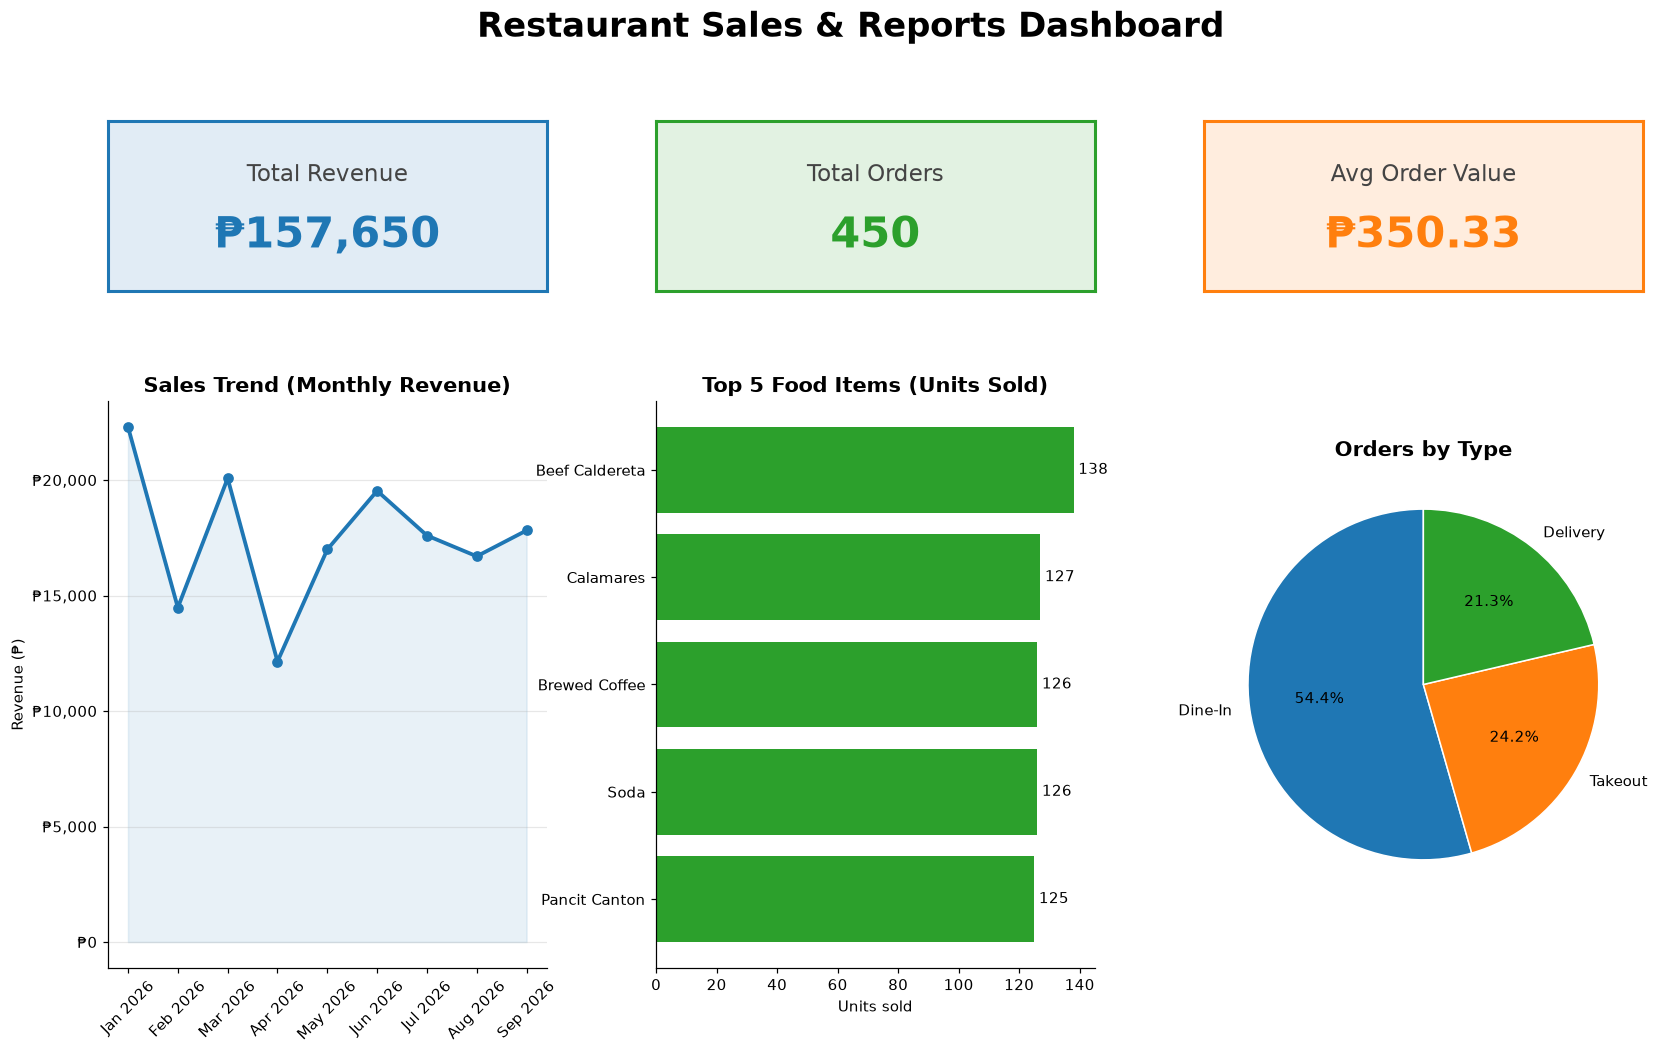

In [13]:
# ---- data for the three charts ----
trend = q4                                   # monthly revenue
top_items = q3.sort_values("units_sold")     # sorted so the biggest bar is on top

if "order_status" in df.columns:
    pie_col, pie_title = "order_status", "Order Status"
else:
    pie_col, pie_title = "order_type", "Orders by Type"
pie_data = df.drop_duplicates("order_id")[pie_col].value_counts()

# ---- layout ----
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[0.6, 2], hspace=0.3, wspace=0.25)
fig.suptitle("Restaurant Sales & Reports Dashboard", fontsize=22, fontweight="bold", y=0.98)

# ---- 3 KPI cards ----
kpis = [("Total Revenue", f"₱{total_revenue:,.0f}", "#1f77b4"),
        ("Total Orders", f"{total_orders:,}", "#2ca02c"),
        ("Avg Order Value", f"₱{avg_order_val:,.2f}", "#ff7f0e")]
for i, (label, value, color) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.set_facecolor(color + "22")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True); s.set_edgecolor(color); s.set_linewidth(2)
    ax.text(0.5, 0.68, label, ha="center", va="center", fontsize=15, color="#444", transform=ax.transAxes)
    ax.text(0.5, 0.32, value, ha="center", va="center", fontsize=28, fontweight="bold", color=color, transform=ax.transAxes)

# ---- Sales trend line chart ----
ax1 = fig.add_subplot(gs[1, 0])
ax1.plot(trend["month_label"], trend["revenue"], marker="o", linewidth=2.5, color="#1f77b4")
ax1.fill_between(range(len(trend)), trend["revenue"], alpha=0.1, color="#1f77b4")
ax1.set_title("Sales Trend (Monthly Revenue)", fontsize=14, fontweight="bold")
ax1.set_ylabel("Revenue (₱)")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("₱{x:,.0f}"))
ax1.tick_params(axis="x", rotation=45)
ax1.grid(axis="y", alpha=0.3)

# ---- Top food items bar chart ----
ax2 = fig.add_subplot(gs[1, 1])
bars = ax2.barh(top_items["item_name"], top_items["units_sold"], color="#2ca02c")
ax2.bar_label(bars, padding=3)
ax2.set_title("Top 5 Food Items (Units Sold)", fontsize=14, fontweight="bold")
ax2.set_xlabel("Units sold")

# ---- Order status / type pie chart ----
ax3 = fig.add_subplot(gs[1, 2])
ax3.pie(pie_data.values, labels=pie_data.index, autopct="%1.1f%%", startangle=90,
        colors=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"][:len(pie_data)],
        wedgeprops={"edgecolor": "white"})
ax3.set_title(pie_title, fontsize=14, fontweight="bold")

fig.savefig("dashboard.png", bbox_inches="tight")
plt.show()